In [1]:
from numpy.lib.stride_tricks import sliding_window_view
import numpy as np

x = np.array([1,2,3,4,5,6,7,8,9,10,11,12,13,14,15])
window_shape = 4

x_w = sliding_window_view(x, window_shape=window_shape)

x_w

array([[ 1,  2,  3,  4],
       [ 2,  3,  4,  5],
       [ 3,  4,  5,  6],
       [ 4,  5,  6,  7],
       [ 5,  6,  7,  8],
       [ 6,  7,  8,  9],
       [ 7,  8,  9, 10],
       [ 8,  9, 10, 11],
       [ 9, 10, 11, 12],
       [10, 11, 12, 13],
       [11, 12, 13, 14],
       [12, 13, 14, 15]])

In [2]:
overlap = 0.5
salto = int(window_shape*(1-overlap))

x_w[::salto]

array([[ 1,  2,  3,  4],
       [ 3,  4,  5,  6],
       [ 5,  6,  7,  8],
       [ 7,  8,  9, 10],
       [ 9, 10, 11, 12],
       [11, 12, 13, 14]])

## Trabjar con EMG de Physionet

In [3]:
!wget -r -N -c -np https://physionet.org/files/emgdb/1.0.0/

--2026-06-10 16:15:27--  https://physionet.org/files/emgdb/1.0.0/
Resolving physionet.org (physionet.org)... 18.13.52.205
Connecting to physionet.org (physionet.org)|18.13.52.205|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘physionet.org/files/emgdb/1.0.0/index.html’

physionet.org/files     [ <=>                ]   1.61K  --.-KB/s    in 0s      

Last-modified header missing -- time-stamps turned off.
2026-06-10 16:15:27 (301 MB/s) - ‘physionet.org/files/emgdb/1.0.0/index.html’ saved [1652]

Loading robots.txt; please ignore errors.
--2026-06-10 16:15:27--  https://physionet.org/robots.txt
Reusing existing connection to physionet.org:443.
HTTP request sent, awaiting response... 200 OK

    The file is already fully retrieved; nothing to do.

--2026-06-10 16:15:27--  https://physionet.org/files/emgdb/1.0.0/RECORDS
Reusing existing connection to physionet.org:443.
HTTP request sent, awaiting response... 304 Not Modified
Fi

In [4]:
path_root="/content/physionet.org/files/emgdb/1.0.0"

!ls {path_root}

emg_healthy.dat   emg_myopathy.hea    emg_neuropathy.txt  SHA256SUMS.txt
emg_healthy.hea   emg_myopathy.txt    emg.png
emg_healthy.txt   emg_neuropathy.dat  index.html
emg_myopathy.dat  emg_neuropathy.hea  RECORDS


In [8]:
import os

path_emg_healthy = os.path.join(path_root, "emg_healthy")
path_emg_healthy

'/content/physionet.org/files/emgdb/1.0.0/emg_healthy'

In [6]:
!pip install wfdb

In [7]:
import wfdb

In [12]:
emg_healthy_rec = wfdb.rdrecord(path_emg_healthy)

emg_healthy = emg_healthy_rec.p_signal.flatten()
emg_healthy

array([-0.0333, -0.035 , -0.035 , ...,  0.005 ,  0.005 ,  0.0083])

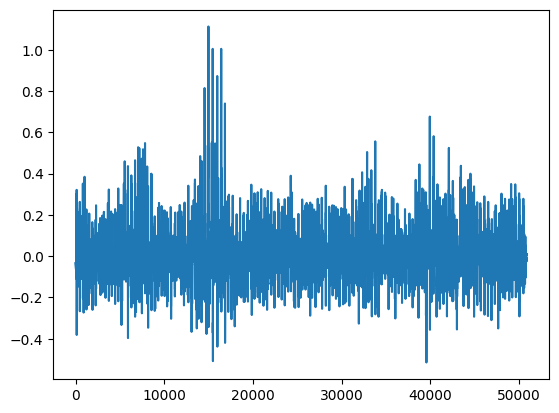

In [13]:
import matplotlib.pyplot as plt

plt.plot(emg_healthy)

In [19]:
fs = emg_healthy_rec.fs
emg_healthy.shape, fs

((50860,), 4000)

In [18]:
window_shape = 2000 # 0.5s
overlap = 0.5
steps = int(window_shape*(1-overlap))

emg_h_w =sliding_window_view(emg_healthy, window_shape=window_shape)[::steps]
emg_h_w.shape

(49, 2000)

In [20]:
emg_h_w[:5,:5]

array([[-0.0333, -0.035 , -0.035 , -0.03  , -0.03  ],
       [ 0.175 ,  0.255 ,  0.2567,  0.2667,  0.2633],
       [ 0.1   ,  0.0667,  0.0583,  0.0567,  0.04  ],
       [-0.1767,  0.1   , -0.145 , -0.0683, -0.0667],
       [-0.0633, -0.0783,  0.1   , -0.08  , -0.0867]])

## Armar la tabla de características

In [24]:
import pandas as pd

df_h = pd.DataFrame(emg_h_w)
df_h.sample(5)

,0,1,2,3,4,5,6,7,8,9,...,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
45,-0.0467,-0.0450,-0.0467,-0.0433,-0.0450,-0.0417,-0.0417,-0.0400,-0.0433,-0.0383,...,-0.0550,-0.0600,-0.0583,-0.0533,-0.0533,-0.0433,-0.0433,-0.0383,-0.0400,-0.0367
5,-0.0833,-0.0833,-0.0700,0.1000,-0.0683,-0.0600,-0.0600,-0.0467,-0.0467,-0.0383,...,0.0350,0.0383,0.0350,0.0367,0.0333,0.0333,0.0283,0.0267,0.0200,0.0183
4,-0.0633,-0.0783,0.1000,-0.0800,-0.0867,-0.0850,-0.0817,-0.0817,-0.0867,-0.0883,...,-0.0150,-0.0217,-0.0200,-0.0100,-0.0100,-0.0017,-0.0017,0.0017,0.0017,-0.0017
2,0.1000,0.0667,0.0583,0.0567,0.0400,0.0417,0.0300,0.0300,0.0333,0.0333,...,-0.0333,0.0700,0.0733,0.0950,0.0900,0.0450,0.0417,-0.0167,-0.0183,-0.0617
35,-0.0183,-0.0183,-0.0150,-0.0150,-0.0133,-0.0133,-0.0150,-0.0133,-0.0117,-0.0117,...,-0.0233,-0.0250,-0.0317,-0.0317,-0.0350,-0.0333,-0.0367,-0.0367,-0.0317,-0.0367


In [25]:
#df_h["target"] = 1
#df_h.head()

In [42]:
df2 = pd.DataFrame()

df2.head()

""


In [43]:
#df2["var"] = df_h.var(axis=1)

#df2.head()

In [44]:
#df2["mean"] = df_h.mean(axis=1)
#df2["std"] = df_h.std(axis=1)
#df2["min"] = df_h.min(axis=1)
#df2["max"] = df_h.max(axis=1)
#df2["median"] = df_h.median(axis=1)
df2["skew"] = df_h.skew(axis=1)
df2["kurt"] = df_h.kurtosis(axis=1)
df2["rms"] = np.sqrt(np.mean(df_h**2, axis=1))
#df2["energy"] = np.sum(df_h**2, axis=1)
df2.head()

,skew,kurt,rms
0,0.028918,4.006996,0.077542
1,0.131739,2.927494,0.058820
2,0.116647,3.763749,0.052631
3,0.661457,4.099726,0.057534
4,0.664992,5.619544,0.077500


<Axes: >

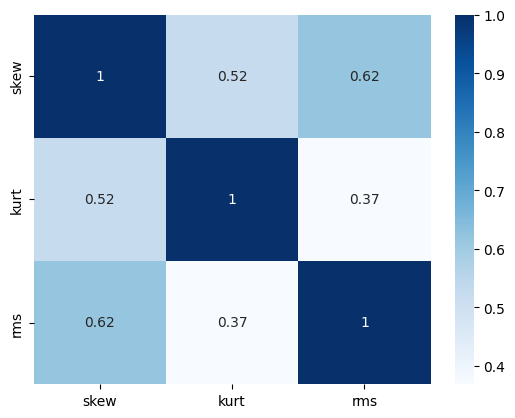

In [45]:
df2_corr = df2.corr()

import seaborn as sns

sns.heatmap(df2_corr, annot=True,cmap="Blues")

In [49]:
from sklearn.decomposition import PCA

df2_trans = PCA(n_components=2).fit_transform(df2)

(-10.0, 10.0)

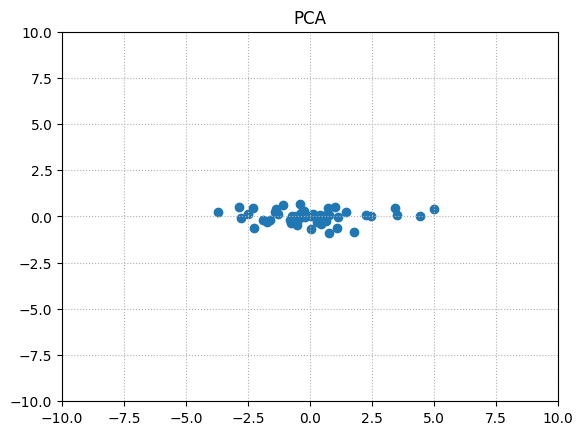

In [51]:
import matplotlib.pyplot as plt

plt.scatter(df2_trans[:,0], df2_trans[:,1])
plt.title("PCA")
plt.grid(ls=":")
plt.xlim(-10,10)
plt.ylim(-10,10)

In [59]:
class Gen_DB_EMG():
    def __init__(self, path_root, window_shape=2000, overlap=0.5):
        self.path_root = path_root
        self.window_shape = window_shape
        self.overlap = overlap

        self.emg, self.fs = self.load_data(self.path_root)
        self.get_db_sig()

    def load_data(self, path):
        #self.path = path
        emg_rec = wfdb.rdrecord(path)
        emg = emg_rec.p_signal.flatten()
        fs = emg_rec.fs

        return emg, fs

    def get_db_sig(self):
        self.steps = int(self.window_shape*(1-self.overlap))
        self.emg_w = sliding_window_view(self.emg, window_shape=self.window_shape)[::self.steps]

        return self.emg_w

    def get_db_features(self, target):
        df = pd.DataFrame(self.emg_w)
        df2 = pd.DataFrame()

        df2["skew"] = df.skew(axis=1)
        df2["kurt"] = df.kurtosis(axis=1)
        df2["rms"] = np.sqrt(np.mean(df**2, axis=1))
        df2["target"] = target

        return df2


In [60]:
!ls {path_root}

emg_healthy.dat   emg_myopathy.hea    emg_neuropathy.txt  SHA256SUMS.txt
emg_healthy.hea   emg_myopathy.txt    emg.png
emg_healthy.txt   emg_neuropathy.dat  index.html
emg_myopathy.dat  emg_neuropathy.hea  RECORDS


In [61]:
path_emg_healthy = os.path.join(path_root, "emg_healthy")
path_emg_myopathy = os.path.join(path_root, "emg_myopathy")
path_emg_neuropathy = os.path.join(path_root, "emg_neuropathy")

In [62]:
sig_emg_h = Gen_DB_EMG(path_emg_healthy)
sig_feature_emg_h= sig_emg_h.get_db_features(target=1)

sig_emg_m = Gen_DB_EMG(path_emg_myopathy)
sig_feature_emg_m= sig_emg_m.get_db_features(target=2)

sig_emg_n = Gen_DB_EMG(path_emg_neuropathy)
sig_feature_emg_n= sig_emg_n.get_db_features(target=3)
#

In [64]:
df_f = pd.concat([sig_feature_emg_h, sig_feature_emg_m, sig_feature_emg_n])
df_f

,skew,kurt,rms,target
0,0.028918,4.006996,0.077542,1
1,0.131739,2.927494,0.058820,1
2,0.116647,3.763749,0.052631,1
3,0.661457,4.099726,0.057534,1
4,0.664992,5.619544,0.077500,1
...,...,...,...,...
141,-0.371773,15.866370,0.458579,3
142,0.771729,17.206037,0.430426,3
143,-0.151342,18.942438,0.439464,3
144,-1.690290,19.127080,0.439827,3


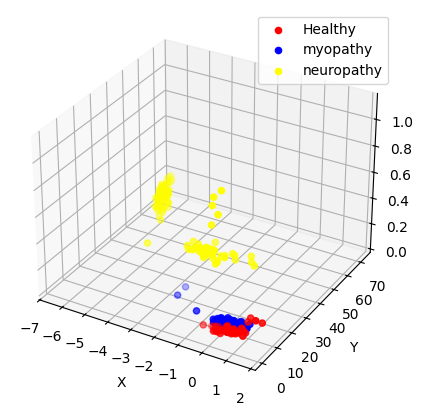

In [72]:

fig = plt.figure(figsize=(10,5))

ax = fig.add_subplot(111, projection="3d")
#ax.scatter(df_f["skew"], df_f["kurt"], df_f["rms"], c=df_f["target"])
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

ax.scatter(
    df_f.query("target==1")["skew"],
    df_f.query("target==1")["kurt"],
    df_f.query("target==1")["rms"],
    c="red",
    label="Healthy"
)

ax.scatter(
    df_f.query("target==2")["skew"],
    df_f.query("target==2")["kurt"],
    df_f.query("target==2")["rms"],
    c="blue",
    label="myopathy"
)

ax.scatter(
    df_f.query("target==3")["skew"],
    df_f.query("target==3")["kurt"],
    df_f.query("target==3")["rms"],
    c="yellow",
    label="neuropathy"
)

ax.legend()

plt.show()

Text(0.5, 0, 'Z')

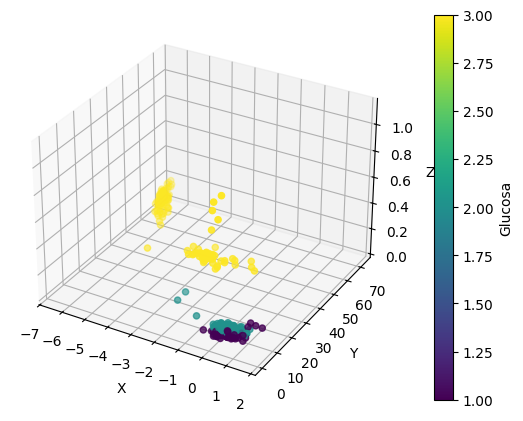

In [71]:
fig = plt.figure(figsize=(10,5))

ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(df_f["skew"], df_f["kurt"], df_f["rms"], c=df_f["target"])
plt.colorbar(scatter, label='Glucosa')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

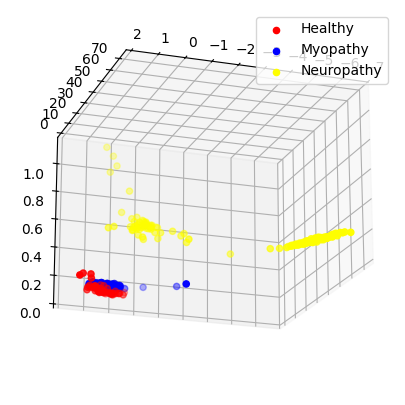

In [103]:
# @title Rotación del gráfico 3D

elev = -19 # @param {type:"slider", min:-90, max:90, step:1}
azim = 71 # @param {type:"slider", min:0, max:360, step:1}

fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    df_f.query("target==1")["skew"],
    df_f.query("target==1")["kurt"],
    df_f.query("target==1")["rms"],
    c="red",
    label="Healthy"
)

ax.scatter(
    df_f.query("target==2")["skew"],
    df_f.query("target==2")["kurt"],
    df_f.query("target==2")["rms"],
    c="blue",
    label="Myopathy"
)

ax.scatter(
    df_f.query("target==3")["skew"],
    df_f.query("target==3")["kurt"],
    df_f.query("target==3")["rms"],
    c="yellow",
    label="Neuropathy"
)

ax.view_init(elev=elev, azim=azim)

ax.legend()
plt.show()

## Machine learning

In [104]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [105]:
df_f.sample(5)

,skew,kurt,rms,target
51,-1.203336,8.217884,0.539890,3
1,0.131739,2.927494,0.058820,1
10,0.075321,7.124123,0.101591,2
108,0.558656,6.088180,0.099051,2
103,0.434237,6.361533,0.096958,2


In [127]:
X = df_f.drop("target", axis=1)
y = df_f["target"]

In [128]:
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y, shuffle=True)
#

In [129]:
from sklearn.ensemble import RandomForestClassifier

In [130]:
model = make_pipeline(StandardScaler(), RandomForestClassifier())
model.fit(X_train, y_train)
#

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('randomforestclassifier', RandomForestClassifier())])

In [131]:
#svc = SVC()
#svc.fit(X_train, y_train)

In [132]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.87      0.87      0.87        15
           2       0.94      0.94      0.94        33
           3       1.00      1.00      1.00        44

    accuracy                           0.96        92
   macro avg       0.94      0.94      0.94        92
weighted avg       0.96      0.96      0.96        92



### Classification Report Analysis

The classification report provides a detailed breakdown of the model's performance for each class. Here's a summary of the results:

*   **Class 1 (Healthy):** The precision, recall, and f1-score are all 0.0. This is because the model did not predict *any* samples as 'Healthy'. This suggests a significant challenge for the model in identifying this class, possibly due to class imbalance or features that do not adequately separate this group.
*   **Class 2 (Myopathy) and Class 3 (Neuropathy):** The model performs much better for these classes, with high precision, recall, and f1-scores. This indicates that the model is quite effective at distinguishing between myopathy and neuropathy.

To get a clearer picture of which classes are being confused, a confusion matrix will be helpful.

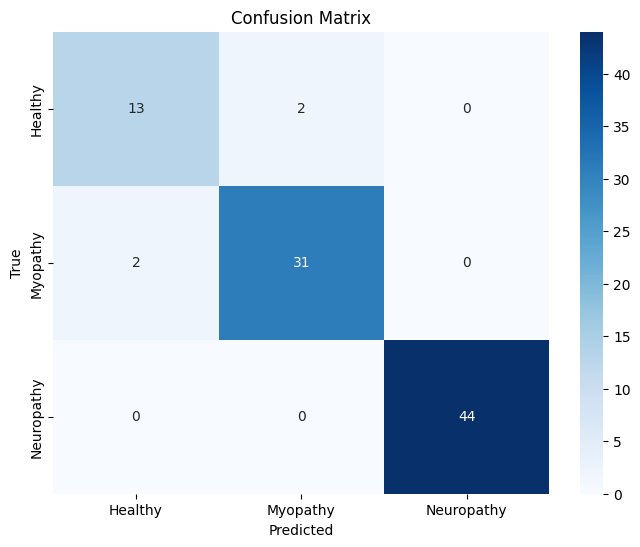

In [133]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy', 'Myopathy', 'Neuropathy'],
            yticklabels=['Healthy', 'Myopathy', 'Neuropathy'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Evaluad el modelo

In [150]:
df_test = df_f.sample(1)
df_test

,skew,kurt,rms,target
6,0.921915,6.693517,0.086251,1


In [151]:
X_new = df_test.drop("target", axis=1)
y_new = df_test["target"]

In [152]:
print("Modelo dice: ",model.predict(X_new),"\nReal es:", y_new.to_numpy())

Modelo dice:  [1] 
Real es: [1]
